# Particles regroup from spatial location instead of initial position

- Particles are released every 5 days, the grouping is not so obvious. We will now group according to the date when they cross certain threshold.

In [7]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from glob import glob

## 1) We randomly select 100 particles from different release stores in one year

In [1]:
path0 = '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'
path0

'/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'

In [18]:
# !ls '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'

In [15]:
stores = np.random.choice(glob(path0+'*2008*.zarr'),size=5,replace=False)
stores

array(['/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-08-16 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-08-21 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-11-24 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-08-01 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-05-13 00:00:00.zarr'],
      dtype='<U106')

In [34]:
ds_list = [xr.open_zarr(s) for s in stores]
ds = xr.concat(ds_list,dim='trajectory')

In [35]:
ds = ds.drop_vars(['z','sal','temp','ndry','nrefine'])
ds

<xarray.Dataset> Size: 898MB
Dimensions:     (trajectory: 50525, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 404kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [36]:
num_valid_obs_steps = int(ds.lat.notnull().any('trajectory').sum().compute().data[()])
ds = ds.isel(obs=slice(None, num_valid_obs_steps))
ds

<xarray.Dataset> Size: 898MB
Dimensions:     (trajectory: 50525, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 404kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [37]:
ds = ds.assign(start_time=ds.time.isel(obs=0).compute())
ds

<xarray.Dataset> Size: 898MB
Dimensions:     (trajectory: 50525, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 404kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 299MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    start_time  (trajectory) datetime64[ns] 404kB 2008-08-16 ... 2008-05-13
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

## 2) Find when they crossed 2.5N,4N,5N,..12N
- Group according the date when they crossed the threshold
- start_time should be then time_treshold

In [38]:
ds = ds.compute()
ds

<xarray.Dataset> Size: 898MB
Dimensions:     (trajectory: 50525, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 404kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 299MB 0.8943 0.9322 ... 17.03 17.04
    lon         (trajectory, obs) float64 299MB -49.76 -49.76 ... -85.75 -85.79
    time        (trajectory, obs) datetime64[ns] 299MB 2008-08-16 ... 2008-11...
    start_time  (trajectory) datetime64[ns] 404kB 2008-08-16 ... 2008-05-13
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [44]:
thr = 2.5
cross = (ds.lat.shift(obs=1) < thr) & (ds.lat >= thr)
crossed = cross.any('obs') # false if it never reaches the threshold
idx = cross.argmax('obs') # obs index of first crossing
idx

<xarray.DataArray 'lat' (trajectory: 50525)> Size: 404kB
array([ 30,  28, 135, ..., 111, 162,  58], shape=(50525,))
Coordinates:
  * trajectory  (trajectory) int64 404kB 0 2 3 5 8 ... 16394 16395 16397 16398

In [48]:
ds = ds.assign(time_treshold=ds.time.isel(obs=idx))
ds

<xarray.Dataset> Size: 899MB
Dimensions:        (trajectory: 50525, obs: 740)
Coordinates:
  * obs            (obs) int32 3kB 0 1 2 3 4 5 6 ... 733 734 735 736 737 738 739
  * trajectory     (trajectory) int64 404kB 0 2 3 5 ... 16394 16395 16397 16398
Data variables:
    lat            (trajectory, obs) float64 299MB 0.8943 0.9322 ... 17.03 17.04
    lon            (trajectory, obs) float64 299MB -49.76 -49.76 ... -85.79
    time           (trajectory, obs) datetime64[ns] 299MB 2008-08-16 ... 2008...
    start_time     (trajectory) datetime64[ns] 404kB 2008-08-16 ... 2008-05-13
    time_treshold  (trajectory) datetime64[ns] 404kB 2008-08-23T12:00:00 ... ...
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [70]:
lat_min=ds.lat.min().compute().data[()]
lon_min=ds.lon.min().compute().data[()]

lat_max=ds.lat.max().compute().data[()]
lon_max=ds.lon.max().compute().data[()]

lat_bins = np.linspace(lat_min, lat_max, 30)
lon_bins = np.linspace(lon_min, lon_max, 80)

In [71]:
def calc_hist(ds):
    return xhist(
        ds.lon,
        ds.lat,
        bins=[lon_bins, lat_bins],
        dim=["trajectory", ],
        bin_dim_suffix=""
    )

In [72]:
ds_m = ds.assign(start_month=ds.start_time.dt.month)
ds_m = ds_m.assign(thr_month=ds.time_treshold.dt.month)
ds_m

<xarray.Dataset> Size: 899MB
Dimensions:        (trajectory: 50525, obs: 740)
Coordinates:
  * obs            (obs) int32 3kB 0 1 2 3 4 5 6 ... 733 734 735 736 737 738 739
  * trajectory     (trajectory) int64 404kB 0 2 3 5 ... 16394 16395 16397 16398
Data variables:
    lat            (trajectory, obs) float64 299MB 0.8943 0.9322 ... 17.03 17.04
    lon            (trajectory, obs) float64 299MB -49.76 -49.76 ... -85.79
    time           (trajectory, obs) datetime64[ns] 299MB 2008-08-16 ... 2008...
    start_time     (trajectory) datetime64[ns] 404kB 2008-08-16 ... 2008-05-13
    time_treshold  (trajectory) datetime64[ns] 404kB 2008-08-23T12:00:00 ... ...
    start_month    (trajectory) int64 404kB 8 8 8 8 8 8 8 8 ... 5 5 5 5 5 5 5 5
    thr_month      (trajectory) int64 404kB 8 8 9 11 8 10 8 9 ... 6 5 6 5 6 6 5
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [73]:
from xhistogram.xarray import histogram as xhist

hist_month = ds_m.groupby(["start_month"]).apply(calc_hist)
# aggregate obs into 5 day bins (with 4 steps each day), skipping the initial positions
hist_month = hist_month.isel(obs=slice(1, None)).coarsen(obs=4 * 5, boundary="trim").sum()


## And the threshold
hist_thr = ds_m.groupby(["thr_month"]).apply(calc_hist)
# aggregate obs into 5 day bins (with 4 steps each day), skipping the initial positions
hist_thr = hist_thr.isel(obs=slice(1, None)).coarsen(obs=4 * 5, boundary="trim").sum()


In [74]:
import cartopy.crs as ccrs
import cartopy.feature as cf
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.patches as mpatches

In [75]:
hist_month

<xarray.DataArray 'histogram_lon_lat' (start_month: 3, obs: 36, lon: 79, lat: 29)> Size: 2MB
array([[[[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
...
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  5,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  2,  0,  0],
         [ 0,  0,  0, ..., 12,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]]]], shape=(3, 36, 79, 29))
Coordinates:
  * obs          (obs) float64 288B 10.5 30.5 50.5 70.5 ... 670.5 690.5 710.5
  * lon          (lon) float64 632B -88.75 -87.91 -87.07 ... -24.98 -24.14 -23.3
  * lat          (lat) float64 232B -0.9697 0.1104 1.19 ... 27.11 28.19 29.27
  * start_month  (start_month) int64 24B 5 8 11

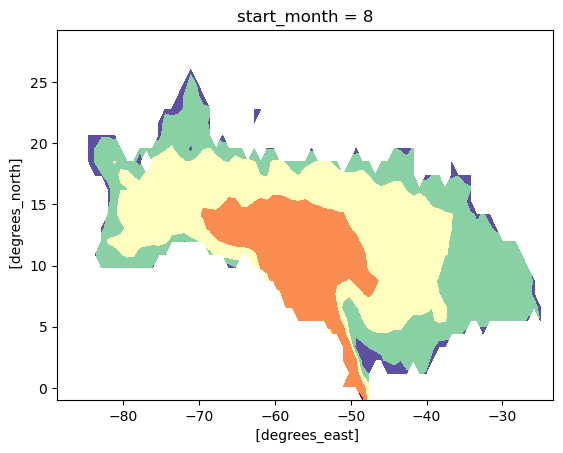

In [82]:
dd = hist_month.isel(start_month=0+1).sum("obs")

    # plot
pcm = np.log10(dd).plot.contourf(
    x='lon', y='lat', 
    add_colorbar=False, cmap='Spectral_r'
    )

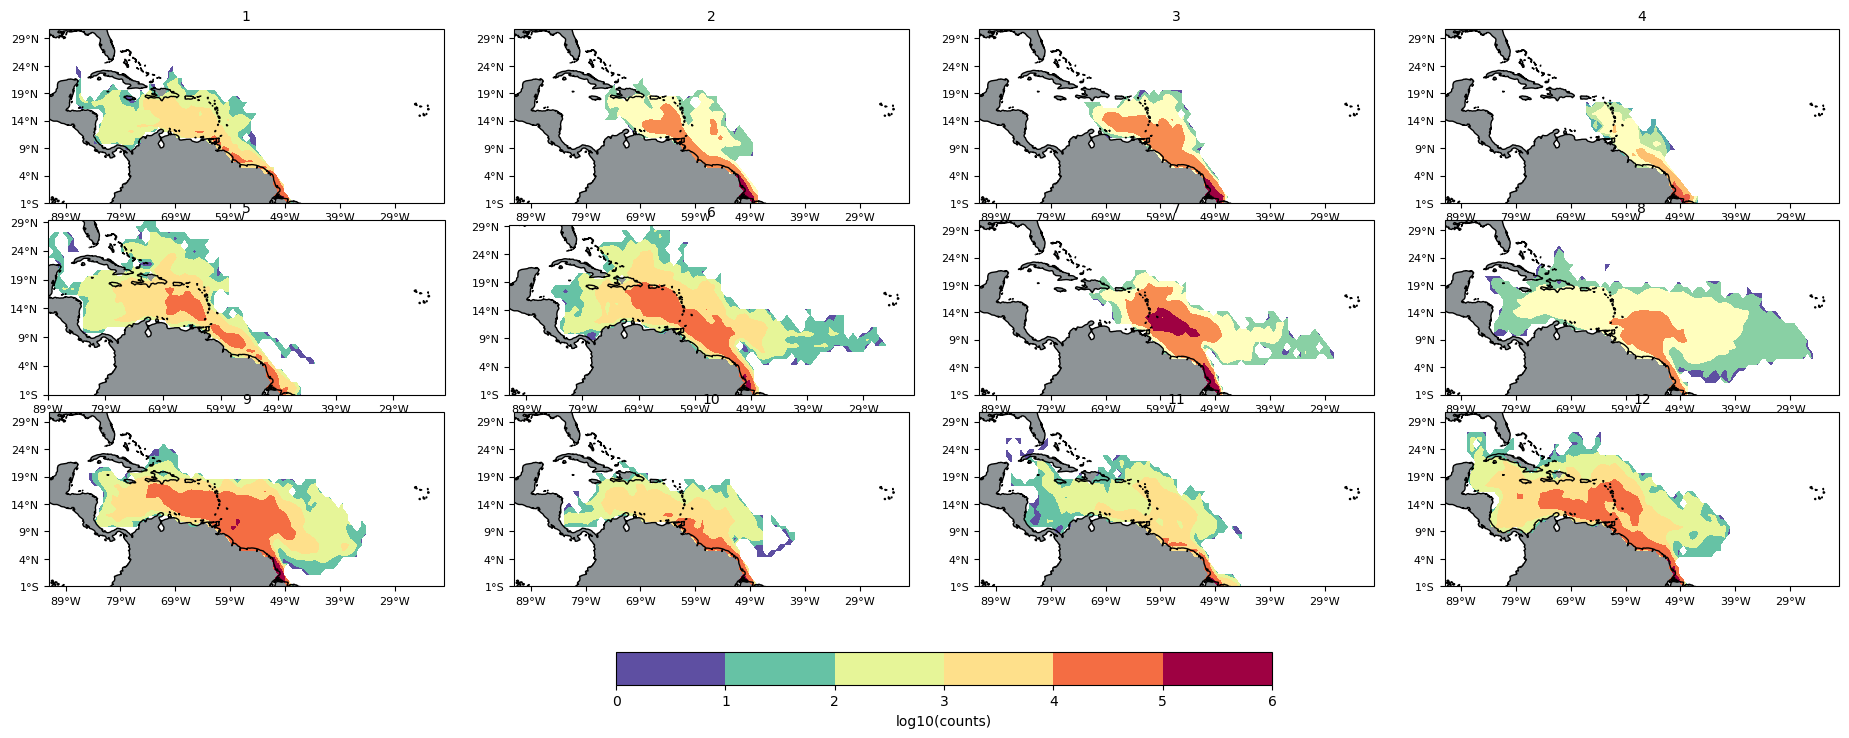

In [101]:
# dd = hist_thr.isel(thr_month=0).sum("obs")

#     # plot
# pcm = np.log10(dd).plot.contourf(
#     x='lon', y='lat', 
#     add_colorbar=False, cmap='Spectral_r'
#     )

proj = ccrs.PlateCarree()

fig, ax = plt.subplots(
    3, 4,
    figsize=(20, 8),                      # a bit wider, not so tall
    subplot_kw=dict(projection=proj)
)
ax = ax.ravel()

for i in range(12):
    dd = hist_thr.sel(thr_month=i+1).sum("obs")

    # plot
    pcm = np.log10(dd).plot.contourf(
        x='lon', y='lat', ax=ax[i], transform=proj,
        add_colorbar=False, cmap='Spectral_r'
    )

    ax[i].coastlines()
    ax[i].add_feature(cf.LAND, facecolor='#8e9497ff', zorder=0)
    ax[i].set_title(i+1, fontsize=10)

    # ticks & labels
    ax[i].set_xticks(
        np.arange(np.floor(dd.lon.min()), np.ceil(dd.lon.max()) + 1e-6, 10),
        crs=proj
    )
    ax[i].set_yticks(
        np.arange(np.floor(dd.lat.min()), np.ceil(dd.lat.max()) + 1e-6, 5),
        crs=proj
    )
    ax[i].xaxis.set_major_formatter(
        LongitudeFormatter(number_format='.0f', degree_symbol='°')
    )
    ax[i].yaxis.set_major_formatter(
        LatitudeFormatter(number_format='.0f', degree_symbol='°')
    )
    ax[i].tick_params(labelsize=8)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')

# Tighter spacing: reduce both wspace and hspace
fig.subplots_adjust(
    left=0.05, right=0.95,
    bottom=0.08, top=0.90,
    wspace=0.15, hspace=0.10
)

# Optional: one shared colorbar at bottom
cbar = fig.colorbar(
    pcm, ax=ax, orientation='horizontal',
    fraction=0.05, pad=0.10
)
cbar.ax.set_xlabel('log10(counts)', fontsize=10)

plt.show()